# DICOM-HUMap-BCRF development

Box-supervised calcification localization with multiscale reliability fusion, center-size-count targets, and a learned residual-risk map.


In [1]:
from __future__ import annotations

import hashlib
import json
import os
import random
import sys
import time
import warnings
from pathlib import Path

from tqdm import TqdmWarning
warnings.filterwarnings("ignore", category=TqdmWarning)

import albumentations as A
import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import average_precision_score
from torch.utils.data import (
    DataLoader,
    Dataset,
    WeightedRandomSampler,
    get_worker_info,
)
from torchvision.models import ResNet18_Weights, resnet18

EXPECTED_PYTHON = Path(os.environ.get("MAMMO_PYTHON", "/home/azyqan/venvs/ml-torch/bin/python")).resolve()
assert Path(sys.executable).resolve() == EXPECTED_PYTHON
assert torch.cuda.is_available()
DEVICE = torch.device("cuda")


import os

_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (_start, *_start.parents)
    if (candidate / "notebooks").is_dir()
    and (candidate / "artifacts").is_dir()
    and (candidate / "dataset").is_dir()
)
DATASET_ROOT = Path(os.environ.get("MAMMO_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
WORK_DATA_ROOT = Path(os.environ.get("MAMMO_WORK_DATA_ROOT", PROJECT_ROOT / "dataset")).expanduser().resolve()
DICOM_ROOT = DATASET_ROOT / "images_dicom"
if not DICOM_ROOT.is_dir() and (DATASET_ROOT / "images").is_dir():
    DICOM_ROOT = DATASET_ROOT / "images"
ANNOTATIONS = DATASET_ROOT / "annotations"
if not ANNOTATIONS.is_dir():
    ANNOTATIONS = DATASET_ROOT
RAW_DIR = WORK_DATA_ROOT / "Raw"
PROCESSED_DIR = WORK_DATA_ROOT / "Processed"
CONFIG_DIR = PROJECT_ROOT / "dataset" / "protocol"
MODEL_DIR = Path(os.environ.get("MAMMO_MODEL_ROOT", WORK_DATA_ROOT / "checkpoints")).expanduser().resolve()
COHORT_TABLES = PROJECT_ROOT / "dataset"
EDA_TABLES = PROJECT_ROOT / "artifacts" / "eda"
MODEL_TABLES = PROJECT_ROOT / "artifacts" / "models"
FIGURE_ROOT = PROJECT_ROOT / "figures"
FIGURE_INDEX = json.loads((FIGURE_ROOT / "index.json").read_text(encoding="utf-8"))
FIGURE_PATHS = {item["source"]: item["path"] for item in FIGURE_INDEX}

def resolve_figure(relative_path: str) -> Path:
    return PROJECT_ROOT / FIGURE_PATHS.get(relative_path, relative_path)

def protocol_table(name: str) -> Path:
    if name in ["bcrf_checkpoint_lineage.csv","bcrf_deployment_lineage.csv","bcrf_freeze_manifest.csv","frozen_evaluation_input_lineage.csv"]:
        return CONFIG_DIR / name
    return MODEL_TABLES / name

def resolve_dicom(relative_path: str) -> Path:
    name = Path(relative_path).name
    direct = DICOM_ROOT / name
    if direct.is_file():
        return direct
    candidates = list(DICOM_ROOT.rglob(name))
    if len(candidates) != 1:
        raise FileNotFoundError(f"Expected one DICOM for {name}; found {len(candidates)}")
    return candidates[0]

def legacy_relative_path(path: Path) -> str:
    if path.name in ["bcrf_checkpoint_lineage.csv", "bcrf_deployment_lineage.csv", "bcrf_freeze_manifest.csv", "frozen_evaluation_input_lineage.csv"]:
        return "Tables/Models/" + path.name
    if path.is_relative_to(MODEL_DIR):
        return "Models/" + str(path.relative_to(MODEL_DIR))
    if path.is_relative_to(WORK_DATA_ROOT / "Raw"):
        return "Data/Raw/" + str(path.relative_to(WORK_DATA_ROOT / "Raw"))
    if path.is_relative_to(PROCESSED_DIR):
        return "Data/Processed/" + str(path.relative_to(PROCESSED_DIR))
    if path.is_relative_to(CONFIG_DIR):
        return "Config/" + str(path.relative_to(CONFIG_DIR))
    if path.is_relative_to(MODEL_TABLES):
        return "Tables/Models/" + str(path.relative_to(MODEL_TABLES))
    return str(path.relative_to(PROJECT_ROOT))

TABLE_DIR = MODEL_TABLES
DEVELOPMENT_FIGURE_DIR = FIGURE_ROOT
FIGURE_DIR = FIGURE_ROOT

FONT_PATH = font_manager.findfont(
    os.environ.get("MAMMO_FONT", "Times New Roman"),
    fallback_to_default=False,
)
mpl.rcParams.update(
    {
        "font.family": os.environ.get("MAMMO_FONT", "Times New Roman"),
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "savefig.dpi": 350,
    }
)

IMAGE_SIZE = 512
MAX_BOXES = 6
SEEDS = (17, 29, 43)
VARIANTS = (
    "full_bcrf",
    "no_morphology",
    "no_center_rank",
    "uniform_fusion",
    "equal_balance",
)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.set_float32_matmul_precision("high")
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def canonical_sha256(payload: dict) -> str:
    raw = json.dumps(
        payload,
        sort_keys=True,
        separators=(",", ":"),
    ).encode()
    return hashlib.sha256(raw).hexdigest()

## Data partitions

Train updates parameters; validation selects checkpoints. Calibration determines the presence threshold after localization is frozen. Retrospective evaluation partitions are excluded from development.


In [2]:
manifest = pd.read_csv(RAW_DIR / "immutable_sample_manifest.csv")
cache_metadata = pd.read_csv(
    PROCESSED_DIR / "standard_dicom_1024_metadata.csv"
)
records = manifest.merge(
    cache_metadata[["image_id", "cache_index", "boxes_1024_json"]],
    on="image_id",
    validate="one_to_one",
)
image_cache = np.load(
    PROCESSED_DIR / "standard_dicom_1024_uint16.npy",
    mmap_mode="r",
)

assert manifest["image_id"].is_unique
assert manifest.groupby("study_id")["split"].nunique().max() == 1
assert manifest["actual_sha256"].eq(manifest["source_sha256"]).all()
assert image_cache.shape == (len(records), 1024, 1024)
assert image_cache.dtype == np.uint16

development = records[
    records["split"].isin(["train", "validation", "calibration"])
].copy()
forbidden = development["split"].isin(
    ["secondary_source_test", "locked_test"]
)
assert not forbidden.any()

split_scope = (
    development.groupby("split", as_index=False)
    .agg(
        images=("image_id", "nunique"),
        studies=("study_id", "nunique"),
        positive_images=("label", "sum"),
    )
)
display(split_scope.style.hide(axis="index"))

split,images,studies,positive_images
calibration,183,101,40
train,745,401,177
validation,182,101,42


## Standard DICOM geometry

The cached input is the standard DICOM rendering defined in NB02. Albumentations transforms image, validity support and boxes synchronously; positive samples revert if a transform removes every target box.

In [3]:
def training_transform(seed: int) -> A.Compose:
    return A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            A.Affine(
                scale=(0.95, 1.05),
                translate_percent=(-0.03, 0.03),
                rotate=(-5.0, 5.0),
                shear=(-2.0, 2.0),
                border_mode=cv2.BORDER_CONSTANT,
                fill=0.0,
                fill_mask=0.0,
                p=0.8,
            ),
        ],
        additional_targets={"valid_mask": "mask"},
        bbox_params=A.BboxParams(
            format="pascal_voc",
            label_fields=["bbox_labels"],
            min_area=1.0,
            min_visibility=0.20,
            clip=True,
            filter_invalid_bboxes=True,
        ),
        seed=seed,
    )

def scale_boxes(boxes_json: str) -> list[list[float]]:
    scaled = []
    for box in json.loads(boxes_json):
        x1, y1, x2, y2 = (
            np.asarray(box, dtype=np.float32) * (IMAGE_SIZE / 1024)
        )
        x1 = float(np.clip(x1, 0, IMAGE_SIZE - 1))
        y1 = float(np.clip(y1, 0, IMAGE_SIZE - 1))
        x2 = float(np.clip(x2, x1, IMAGE_SIZE))
        y2 = float(np.clip(y2, y1, IMAGE_SIZE))
        if x2 > x1 and y2 > y1:
            scaled.append([x1, y1, x2, y2])
    return scaled[:MAX_BOXES]

CENTER_STRIDE = 4
CENTER_SIZE = IMAGE_SIZE // CENTER_STRIDE

def boxes_to_targets(
    boxes: list[list[float]],
    valid_mask: np.ndarray,
) -> dict[str, np.ndarray]:
    yy, xx = np.mgrid[:CENTER_SIZE, :CENTER_SIZE]
    density = np.zeros((CENTER_SIZE, CENTER_SIZE), np.float32)
    center_mask = np.zeros_like(density)
    size_target = np.zeros((2, CENTER_SIZE, CENTER_SIZE), np.float32)
    offset_target = np.zeros_like(size_target)
    for x1, y1, x2, y2 in boxes:
        scaled = np.asarray([x1, y1, x2, y2]) / CENTER_STRIDE
        sx1, sy1, sx2, sy2 = scaled
        center_x = (sx1 + sx2) / 2
        center_y = (sy1 + sy2) / 2
        grid_x = int(np.clip(np.floor(center_x), 0, CENTER_SIZE - 1))
        grid_y = int(np.clip(np.floor(center_y), 0, CENTER_SIZE - 1))
        sigma_x = max((sx2 - sx1) / 6, 0.75)
        sigma_y = max((sy2 - sy1) / 6, 0.75)
        gaussian = np.exp(
            -0.5
            * (
                ((xx - center_x) / sigma_x) ** 2
                + ((yy - center_y) / sigma_y) ** 2
            )
        )
        density = np.maximum(density, gaussian.astype(np.float32))
        center_mask[grid_y, grid_x] = 1.0
        width = max(x2 - x1, 1.0) / IMAGE_SIZE
        height = max(y2 - y1, 1.0) / IMAGE_SIZE
        size_target[:, grid_y, grid_x] = np.log([width, height])
        offset_target[:, grid_y, grid_x] = [
            center_x - grid_x,
            center_y - grid_y,
        ]
    valid_native = cv2.resize(
        valid_mask.astype(np.uint8),
        (CENTER_SIZE, CENTER_SIZE),
        interpolation=cv2.INTER_NEAREST,
    ).astype(np.float32)
    return {
        "center_density": density * valid_native,
        "center_mask": center_mask * valid_native,
        "size_target": size_target,
        "offset_target": offset_target,
        "valid_native": valid_native,
        "count_target": np.int64(min(len(boxes), MAX_BOXES)),
    }

In [4]:
class MammographyDataset(Dataset):
    def __init__(
        self,
        frame: pd.DataFrame,
        training: bool,
        seed: int,
    ) -> None:
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = training_transform(seed) if training else None

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict:
        row = self.frame.iloc[index]
        source = image_cache[int(row.cache_index)].astype(np.float32)
        source /= 65535.0
        image = cv2.resize(
            source,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_AREA,
        )
        valid_mask = cv2.resize(
            (source > 0).astype(np.uint8),
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST,
        )
        boxes = scale_boxes(row.boxes_1024_json)
        original = image.copy(), valid_mask.copy(), list(boxes)

        if self.transform is not None:
            transformed = self.transform(
                image=image,
                valid_mask=valid_mask,
                bboxes=boxes,
                bbox_labels=[1] * len(boxes),
            )
            image = transformed["image"]
            valid_mask = transformed["valid_mask"]
            boxes = [list(box) for box in transformed["bboxes"]]
            if int(row.label) == 1 and not boxes:
                image, valid_mask, boxes = original

        valid_mask = (valid_mask > 0).astype(np.float32)
        targets = boxes_to_targets(boxes, valid_mask)
        padded_boxes = np.full((MAX_BOXES, 4), -1.0, np.float32)
        box_valid = np.zeros(MAX_BOXES, dtype=np.bool_)
        for box_index, box in enumerate(boxes):
            padded_boxes[box_index] = box
            box_valid[box_index] = True

        assert np.isfinite(image).all()
        assert np.isfinite(padded_boxes[box_valid]).all()
        return {
            "image": torch.from_numpy(image[None]).float(),
            "valid_mask": torch.from_numpy(valid_mask[None]).float(),
            "center_density": torch.from_numpy(
                targets["center_density"][None]
            ).float(),
            "center_mask": torch.from_numpy(
                targets["center_mask"][None]
            ).float(),
            "size_target": torch.from_numpy(
                targets["size_target"]
            ).float(),
            "offset_target": torch.from_numpy(
                targets["offset_target"]
            ).float(),
            "valid_native": torch.from_numpy(
                targets["valid_native"][None]
            ).float(),
            "count_target": torch.tensor(
                targets["count_target"],
                dtype=torch.long,
            ),
            "boxes": torch.from_numpy(padded_boxes),
            "box_valid": torch.from_numpy(box_valid),
            "label": torch.tensor(float(row.label)),
            "image_id": row.image_id,
            "study_id": row.study_id,
        }

def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    worker = get_worker_info()
    if worker is not None and worker.dataset.transform is not None:
        worker.dataset.transform.set_random_seed(int(worker_seed))

In [5]:
def make_loader(
    frame: pd.DataFrame,
    training: bool,
    seed: int,
    batch_size: int = 4,
) -> DataLoader:
    generator = torch.Generator().manual_seed(seed)
    sampler = None
    if training:
        class_counts = frame["label"].value_counts()
        sample_weights = frame["label"].map(
            lambda label: 1.0 / class_counts.loc[label]
        )
        sampler = WeightedRandomSampler(
            torch.as_tensor(
                sample_weights.to_numpy(copy=True),
                dtype=torch.double,
            ),
            num_samples=len(frame),
            replacement=True,
            generator=generator,
        )
    return DataLoader(
        MammographyDataset(frame, training, seed),
        batch_size=batch_size,
        shuffle=False,
        sampler=sampler,
        num_workers=4,
        pin_memory=True,
        persistent_workers=True,
        worker_init_fn=seed_worker,
        generator=generator,
        drop_last=training,
    )


def move_batch(batch: dict) -> dict:
    moved = dict(batch)
    for key in (
        "image",
        "valid_mask",
        "center_density",
        "center_mask",
        "size_target",
        "offset_target",
        "valid_native",
        "count_target",
        "boxes",
        "box_valid",
        "label",
    ):
        moved[key] = moved[key].to(DEVICE, non_blocking=True)
    return moved


sanity_dataset = MammographyDataset(
    records[records["split"].eq("train")].head(32),
    training=True,
    seed=SEEDS[0],
)
for sanity_index in range(len(sanity_dataset)):
    sample = sanity_dataset[sanity_index]
    boxes = sample["boxes"][sample["box_valid"]]
    assert torch.isfinite(boxes).all()
    assert ((boxes[:, :2] >= 0) & (boxes[:, 2:] <= IMAGE_SIZE)).all()
    assert (boxes[:, 2:] > boxes[:, :2]).all()


## Hybrid box-supervised architecture

The proposed configuration combines valid-region image-global reliability, learnable zero-DC morphology, bbox-derived centre-size targets, localization-conditioned decisions, and a learned residual-risk map.

In [6]:
def pretrained_resnet18() -> nn.Module:
    return resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

class FrozenBatchNormMixin:
    def train(self, mode: bool = True):
        super().train(mode)
        for module in self.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
        return self

class ConvGNAct(nn.Sequential):
    def __init__(self, input_channels: int, output_channels: int):
        super().__init__(
            nn.Conv2d(
                input_channels,
                output_channels,
                3,
                padding=1,
                bias=False,
            ),
            nn.GroupNorm(8, output_channels),
            nn.SiLU(),
        )

class ZeroDCDepthwise(nn.Module):
    def __init__(self, channels: int, enabled: bool):
        super().__init__()
        self.enabled = enabled
        self.weight = nn.Parameter(torch.empty(channels, 1, 5, 5))
        nn.init.kaiming_normal_(self.weight)
        self.bias = nn.Parameter(torch.zeros(channels))

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        if not self.enabled:
            return torch.zeros_like(features)
        weight = self.weight
        if self.enabled:
            weight = weight - weight.mean((-2, -1), keepdim=True)
        return F.conv2d(
            features,
            weight,
            self.bias,
            padding=2,
            groups=features.shape[1],
        )

class MultiScaleEncoder(FrozenBatchNormMixin, nn.Module):
    def __init__(self, morphology: bool):
        super().__init__()
        network = pretrained_resnet18()
        self.register_buffer(
            "imagenet_mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1),
        )
        self.register_buffer(
            "imagenet_std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1),
        )
        self.stem = nn.Sequential(
            network.conv1,
            network.bn1,
            network.relu,
            network.maxpool,
        )
        self.layer1 = network.layer1
        self.layer2 = network.layer2
        self.layer3 = network.layer3
        self.morphology = ZeroDCDepthwise(64, morphology)
        self.morph_fuse = ConvGNAct(128, 64)
        self.lateral2 = nn.Conv2d(64, 64, 1)
        self.lateral3 = nn.Conv2d(128, 64, 1)
        self.lateral4 = nn.Conv2d(256, 64, 1)
        self.smooth2 = ConvGNAct(64, 64)
        self.smooth3 = ConvGNAct(64, 64)
        self.smooth4 = ConvGNAct(64, 64)

    def forward(self, image: torch.Tensor) -> tuple[torch.Tensor, ...]:
        encoded = image.repeat(1, 3, 1, 1)
        encoded = (encoded - self.imagenet_mean) / self.imagenet_std
        c2 = self.layer1(self.stem(encoded))
        morph = F.silu(self.morphology(c2))
        c2 = self.morph_fuse(torch.cat([c2, morph], 1))
        c3 = self.layer2(c2)
        c4 = self.layer3(c3)
        p4 = self.smooth4(self.lateral4(c4))
        p3 = self.smooth3(
            self.lateral3(c3)
            + F.interpolate(p4, c3.shape[-2:], mode="bilinear",
                align_corners=False,
            )
        )
        p2 = self.smooth2(
            self.lateral2(c2)
            + F.interpolate(p3, c2.shape[-2:], mode="bilinear",
                align_corners=False,
            )
        )
        return p2, p3, p4, c4

In [7]:
def binary_entropy(probability: torch.Tensor) -> torch.Tensor:
    probability = probability.float().clamp(1e-4, 1 - 1e-4)
    return -(
        probability * probability.log()
        + (1 - probability) * (1 - probability).log()
    )

class DICOMHUMapBCRF(nn.Module):
    def __init__(self, variant: str):
        super().__init__()
        assert variant in VARIANTS
        self.variant = variant
        morphology = variant != "no_morphology"
        self.encoder = MultiScaleEncoder(morphology=morphology)
        self.detail = nn.Sequential(
            ConvGNAct(1, 16),
            ZeroDCDepthwise(16, morphology),
            ConvGNAct(16, 16),
        )
        self.detail_heat_head = nn.Conv2d(16, 1, 1)
        self.detail_reliability_head = nn.Conv2d(16, 1, 1)
        self.heat_heads = nn.ModuleList(
            [nn.Conv2d(64, 1, 1) for _ in range(3)]
        )
        self.reliability_heads = nn.ModuleList(
            [nn.Conv2d(64, 1, 1) for _ in range(3)]
        )
        self.log_size_head = nn.Sequential(
            ConvGNAct(64, 32),
            nn.Conv2d(32, 2, 1),
        )
        self.offset_head = nn.Sequential(
            ConvGNAct(64, 32),
            nn.Conv2d(32, 2, 1),
        )
        def decision_projection() -> nn.Sequential:
            return nn.Sequential(
                nn.Linear(320, 128),
                nn.LayerNorm(128),
                nn.GELU(),
                nn.Dropout(0.10),
            )
        self.presence_projection = decision_projection()
        self.count_projection = decision_projection()
        self.presence_head = nn.Linear(128, 2)
        self.count_head = nn.Linear(128, MAX_BOXES)
        self.constraint_uncertainty = nn.Sequential(
            ConvGNAct(64, 32),
            nn.Conv2d(32, 1, 1),
        )
        self.uncertainty_fusion = nn.Sequential(
            nn.Conv2d(2, 8, 1),
            nn.GELU(),
            nn.Conv2d(8, 1, 1),
        )

    def forward(
        self,
        image: torch.Tensor,
        valid_mask: torch.Tensor,
    ) -> dict[str, torch.Tensor]:
        p2, p3, p4, semantic = self.encoder(image)
        native_shape = p2.shape[-2:]
        scale_logits = []
        reliability_logits = []
        for feature, heat_head, reliability_head in zip(
            (p2, p3, p4),
            self.heat_heads,
            self.reliability_heads,
        ):
            scale_logits.append(
                F.interpolate(
                    heat_head(feature),
                    native_shape,
                    mode="bilinear",
                    align_corners=False,
                )
            )
            reliability_logits.append(
                F.interpolate(
                    reliability_head(feature),
                    native_shape,
                    mode="bilinear",
                    align_corners=False,
                )
            )
        detail = F.avg_pool2d(
            self.detail(image),
            kernel_size=CENTER_STRIDE,
            stride=CENTER_STRIDE,
        )
        scale_logits.append(self.detail_heat_head(detail))
        reliability_logits.append(
            self.detail_reliability_head(detail)
        )
        scale_logits = torch.stack(scale_logits, dim=1)
        scale_probabilities = torch.sigmoid(scale_logits)
        valid_native = F.interpolate(
            valid_mask.float(),
            native_shape,
            mode="nearest",
        )
        if self.variant == "uniform_fusion":
            scale_weights = torch.ones_like(scale_logits)
            scale_weights /= scale_weights.shape[1]
        else:
            reliability_stack = torch.stack(
                reliability_logits,
                dim=1,
            )
            valid_stack = valid_native.unsqueeze(1)
            global_reliability = (
                reliability_stack * valid_stack
            ).sum((-2, -1), keepdim=True) / valid_stack.sum(
                (-2, -1), keepdim=True
            ).clamp_min(1)
            scale_weights = torch.softmax(
                global_reliability,
                dim=1,
            )
        center_probability = (
            scale_weights * scale_probabilities
        ).sum(1)
        weighted_entropy = (
            scale_weights * binary_entropy(scale_probabilities)
        ).sum(1)
        disagreement = (
            binary_entropy(center_probability) - weighted_entropy
        ).clamp_min(0) / np.log(2)
        learned_uncertainty_native = torch.sigmoid(
            self.constraint_uncertainty(p2.detach())
        )
        center_probability = center_probability * valid_native
        learned_uncertainty_native = (
            learned_uncertainty_native * valid_native
        )
        disagreement = disagreement * valid_native
        uncertainty_native = torch.sigmoid(
            self.uncertainty_fusion(
                torch.cat(
                    [
                        learned_uncertainty_native,
                        disagreement.detach(),
                    ],
                    dim=1,
                )
            )
        ) * valid_native
        heatmap = F.interpolate(
            center_probability,
            image.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ) * valid_mask
        uncertainty = F.interpolate(
            uncertainty_native,
            image.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ) * valid_mask
        pooled_semantic = semantic.mean((-2, -1))
        attention = center_probability / center_probability.sum(
            (-2, -1),
            keepdim=True,
        ).clamp_min(1e-6)
        attended_p2 = (p2 * attention).sum((-2, -1))
        decision_input = torch.cat(
            [pooled_semantic, attended_p2],
            dim=1,
        )
        presence_features = self.presence_projection(decision_input)
        count_features = self.count_projection(decision_input)
        presence_class_logits = self.presence_head(presence_features)
        count_logits = self.count_head(count_features)
        presence_logits = (
            presence_class_logits[:, 1]
            - presence_class_logits[:, 0]
        )
        return {
            "heatmap": heatmap,
            "center_probability": center_probability,
            "scale_probabilities": scale_probabilities,
            "scale_weights": scale_weights,
            "log_size": self.log_size_head(p2),
            "offset": torch.sigmoid(self.offset_head(p2)),
            "presence_class_logits": presence_class_logits,
            "count_logits": count_logits,
            "presence_logits": presence_logits,
            "learned_uncertainty_native": learned_uncertainty_native,
            "uncertainty_native": uncertainty_native,
            "disagreement_native": disagreement,
            "uncertainty": uncertainty,
        }

class LogCompressedLossBalance(nn.Module):
    def __init__(self, names: tuple[str, ...]):
        super().__init__()
        self.names = names
    def forward(self, losses: dict[str, torch.Tensor]) -> torch.Tensor:
        values = torch.stack([losses[name] for name in self.names])
        return torch.log1p(values).mean()


In [8]:
LOSS_NAMES = (
    "center_positive",
    "center_negative",
    "center_distribution",
    "center_rank",
    "log_size",
    "offset",
    "presence",
    "count",
    "uncertainty",
)

def center_likelihood_losses(
    probability: torch.Tensor,
    target: torch.Tensor,
    center_mask: torch.Tensor,
    valid_mask: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    probability = probability.float().clamp(1e-4, 1 - 1e-4)
    positive_mass = center_mask.sum((-3, -2, -1))
    positive_per_image = -(
        center_mask * probability.log()
    ).sum((-3, -2, -1)) / positive_mass.clamp_min(1)
    positive = (
        positive_per_image[positive_mass > 0].mean()
        if bool((positive_mass > 0).any())
        else probability.sum() * 0
    )
    negative_weights = (
        (1 - target) * (1 - center_mask) * valid_mask
    )
    negative = -(
        negative_weights * torch.log1p(-probability)
    ).sum((-3, -2, -1)) / negative_weights.sum(
        (-3, -2, -1)
    ).clamp_min(1)
    return positive, negative.mean()

def center_distribution_loss(
    probability: torch.Tensor,
    target: torch.Tensor,
    valid_mask: torch.Tensor,
) -> torch.Tensor:
    target_mass = target.sum((-3, -2, -1))
    positive_images = target_mass > 0
    if not bool(positive_images.any()):
        return probability.sum() * 0
    prediction = probability[positive_images] * valid_mask[positive_images]
    target_positive = target[positive_images]
    prediction_distribution = prediction / prediction.sum(
        (-3, -2, -1),
        keepdim=True,
    ).clamp_min(1e-6)
    target_distribution = target_positive / target_positive.sum(
        (-3, -2, -1),
        keepdim=True,
    ).clamp_min(1e-6)
    return -(
        target_distribution
        * prediction_distribution.clamp_min(1e-8).log()
    ).sum((-3, -2, -1)).mean()

def center_rank_loss(
    probability: torch.Tensor,
    boxes: torch.Tensor,
    box_valid: torch.Tensor,
) -> torch.Tensor:
    logits = torch.logit(probability.clamp(1e-6, 1 - 1e-6))
    terms = []
    for batch_index in range(probability.shape[0]):
        for box_index in torch.where(box_valid[batch_index])[0]:
            x1, y1, x2, y2 = boxes[batch_index, box_index] / CENTER_STRIDE
            ix1 = int(torch.floor(x1).clamp(0, CENTER_SIZE - 1))
            iy1 = int(torch.floor(y1).clamp(0, CENTER_SIZE - 1))
            ix2 = min(int(torch.ceil(x2)) + 1, CENTER_SIZE)
            iy2 = min(int(torch.ceil(y2)) + 1, CENTER_SIZE)
            center_x = int(torch.floor((x1 + x2) / 2).clamp(0, CENTER_SIZE - 1))
            center_y = int(torch.floor((y1 + y2) / 2).clamp(0, CENTER_SIZE - 1))
            center_logit = logits[batch_index, 0, center_y, center_x]
            region = logits[batch_index, 0, iy1:iy2, ix1:ix2].clone()
            region[center_y - iy1, center_x - ix1] = -torch.inf
            competitor = region.max()
            if torch.isfinite(competitor):
                terms.append(F.softplus(competitor - center_logit))
    if terms:
        return torch.stack(terms).mean()
    return probability.sum() * 0

In [9]:
def box_set_losses(
    output: dict[str, torch.Tensor],
    batch: dict,
    variant: str,
) -> dict[str, torch.Tensor]:
    center_terms = [
        center_likelihood_losses(
            branch,
            batch["center_density"],
            batch["center_mask"],
            batch["valid_native"],
        )
        for branch in (
            output["center_probability"],
            *output["scale_probabilities"].unbind(1),
        )
    ]
    center_positive = torch.stack(
        [term[0] for term in center_terms]
    ).mean()
    center_negative = torch.stack(
        [term[1] for term in center_terms]
    ).mean()
    center_distribution = torch.stack(
        [
            center_distribution_loss(
                branch,
                batch["center_density"],
                batch["valid_native"],
            )
            for branch in (
                output["center_probability"],
                *output["scale_probabilities"].unbind(1),
            )
        ]
    ).mean()
    center_rank = center_rank_loss(
        output["center_probability"],
        batch["boxes"],
        batch["box_valid"],
    )
    geometry_mask = batch["center_mask"].expand(-1, 2, -1, -1)
    geometry_denominator = geometry_mask.sum().clamp_min(1)
    log_size = F.smooth_l1_loss(
        output["log_size"] * geometry_mask,
        batch["size_target"] * geometry_mask,
        reduction="sum",
    ) / geometry_denominator
    offset = F.smooth_l1_loss(
        output["offset"] * geometry_mask,
        batch["offset_target"] * geometry_mask,
        reduction="sum",
    ) / geometry_denominator
    presence_target = (batch["count_target"] > 0).long()
    presence = F.cross_entropy(
        output["presence_class_logits"],
        presence_target,
    )
    positive_images = presence_target > 0
    count = (
        F.cross_entropy(
            output["count_logits"][positive_images],
            batch["count_target"][positive_images] - 1,
        )
        if bool(positive_images.any())
        else output["count_logits"].sum() * 0
    )
    residual_target = (
        output["center_probability"].detach()
        - batch["center_density"]
    ).abs() * batch["valid_native"]
    uncertainty = F.smooth_l1_loss(
        output["uncertainty_native"],
        residual_target,
        reduction="sum",
    ) / batch["valid_native"].sum().clamp_min(1)
    return {
        "center_positive": center_positive,
        "center_negative": center_negative,
        "center_distribution": center_distribution,
        "center_rank": center_rank,
        "log_size": log_size,
        "offset": offset,
        "presence": presence,
        "count": count,
        "uncertainty": uncertainty,
    }

def active_loss_names(variant: str) -> tuple[str, ...]:
    return tuple(
        name
        for name in LOSS_NAMES
        if not (variant == "no_center_rank" and name == "center_rank")
    )

def total_loss(
    output: dict[str, torch.Tensor],
    batch: dict,
    variant: str,
    balancer: LogCompressedLossBalance,
) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
    losses = box_set_losses(output, batch, variant)
    names = active_loss_names(variant)
    active_losses = {name: losses[name] for name in names}
    if variant == "equal_balance":
        combined = torch.stack(list(active_losses.values())).mean()
    else:
        combined = balancer(active_losses)
    return combined, losses

## Training configuration

Five architecture variants use the same partitions, three seeds, augmentation, optimizer, and epoch budget. Checkpoints are selected by validation localization metrics.


In [10]:
TRAIN_BOX_COUNTS = records.loc[
    records["split"].eq("train") & records["label"].eq(1),
    "boxes_1024_json",
].map(lambda value: len(json.loads(value)))
MAX_PREDICTED_BOXES = int(np.quantile(TRAIN_BOX_COUNTS, 0.90))
assert 1 <= MAX_PREDICTED_BOXES <= MAX_BOXES

def normalize_map(array: np.ndarray) -> np.ndarray:
    minimum = float(array.min())
    maximum = float(array.max())
    return (array - minimum) / max(maximum - minimum, 1e-6)

def continuous_iou(
    first: list[float],
    second: list[float],
) -> float:
    x1, y1 = max(first[0], second[0]), max(first[1], second[1])
    x2, y2 = min(first[2], second[2]), min(first[3], second[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_first = max(0, first[2] - first[0]) * max(
        0, first[3] - first[1]
    )
    area_second = max(0, second[2] - second[0]) * max(
        0, second[3] - second[1]
    )
    return intersection / max(
        area_first + area_second - intersection,
        1e-8,
    )

def matched_localization(
    predicted: list[list[float]],
    target: list[list[float]],
) -> dict[str, float]:
    denominator = max(len(predicted), len(target), 1)
    if not predicted or not target:
        return {
            "matched_iou": 0.0,
            "penalized_iou": 0.0,
            "box_recall_0_1": 0.0,
            "false_positive_boxes": float(len(predicted)),
        }
    matrix = np.asarray(
        [
            [continuous_iou(first, second) for second in target]
            for first in predicted
        ]
    )
    rows, columns = linear_sum_assignment(1 - matrix)
    matched = matrix[rows, columns]
    return {
        "matched_iou": float(matched.mean()),
        "penalized_iou": float(matched.sum() / denominator),
        "box_recall_0_1": float((matched >= 0.10).sum() / len(target)),
        "false_positive_boxes": float(
            len(predicted) - (matched >= 0.10).sum()
        ),
    }

def decode_conditional_box_set(
    output: dict[str, torch.Tensor],
    batch_index: int,
) -> list[list[float]]:
    predicted_count = int(
        output["count_logits"][batch_index].argmax().item()
    ) + 1
    if predicted_count == 0:
        return []
    center = output["center_probability"][batch_index, 0]
    local_maximum = center.eq(
        F.max_pool2d(
            center[None, None],
            kernel_size=3,
            stride=1,
            padding=1,
        )[0, 0]
    )
    scores = center.masked_fill(~local_maximum, -1)
    top_scores, top_indices = scores.flatten().topk(
        min(predicted_count, MAX_PREDICTED_BOXES)
    )
    decoded = []
    for score, flat_index in zip(top_scores, top_indices):
        if not torch.isfinite(score) or float(score) < 0:
            continue
        grid_y = int(flat_index // CENTER_SIZE)
        grid_x = int(flat_index % CENTER_SIZE)
        offset = output["offset"][batch_index, :, grid_y, grid_x]
        log_size = output["log_size"][
            batch_index,
            :,
            grid_y,
            grid_x,
        ].clamp(-np.log(IMAGE_SIZE), 0)
        width, height = torch.exp(log_size) * IMAGE_SIZE
        center_x = (grid_x + float(offset[0])) * CENTER_STRIDE
        center_y = (grid_y + float(offset[1])) * CENTER_STRIDE
        width = float(width.clamp(1, IMAGE_SIZE))
        height = float(height.clamp(1, IMAGE_SIZE))
        decoded.append(
            [
                max(0.0, center_x - width / 2),
                max(0.0, center_y - height / 2),
                min(float(IMAGE_SIZE), center_x + width / 2),
                min(float(IMAGE_SIZE), center_y + height / 2),
            ]
        )
    return decoded

In [11]:
@torch.no_grad()
def evaluate_model(
    model: nn.Module,
    loader: DataLoader,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    model.eval()
    predictions = []
    for batch in loader:
        batch = move_batch(batch)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model(batch["image"], batch["valid_mask"])
        heatmaps = output["heatmap"].float().cpu().numpy()[:, 0]
        uncertainty = output["uncertainty"].float().cpu().numpy()[:, 0]
        probabilities = torch.sigmoid(
            output["presence_logits"]
        ).float().cpu().numpy()
        predicted_counts = torch.where(
            output["presence_class_logits"].argmax(1).eq(1),
            output["count_logits"].argmax(1) + 1,
            torch.zeros_like(output["count_logits"].argmax(1)),
        )
        for index, image_id in enumerate(batch["image_id"]):
            target_valid = batch["box_valid"][index]
            target = batch["boxes"][index, target_valid].cpu().tolist()
            conditional = decode_conditional_box_set(output, index)
            requested_count = int(predicted_counts[index].item())
            system = conditional[:requested_count] if requested_count else []
            conditional_metrics = matched_localization(conditional, target)
            system_metrics = matched_localization(system, target)
            valid = batch["valid_mask"][index, 0].cpu().numpy() > 0
            normalized_heatmap = normalize_map(heatmaps[index])
            target_union = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=bool)
            for x1, y1, x2, y2 in target:
                target_union[
                    int(np.floor(y1)):min(int(np.ceil(y2)) + 1, IMAGE_SIZE),
                    int(np.floor(x1)):min(int(np.ceil(x2)) + 1, IMAGE_SIZE),
                ] = True
            peak_y, peak_x = np.unravel_index(
                int(np.argmax(normalized_heatmap * valid)),
                normalized_heatmap.shape,
            )
            predictions.append(
                {
                    "image_id": image_id,
                    "study_id": batch["study_id"][index],
                    "label": int(batch["label"][index].item()),
                    "presence_probability": float(probabilities[index]),
                    "conditional_count": len(conditional),
                    "predicted_count": len(system),
                    "target_count": int(batch["count_target"][index].item()),
                    "count_correct": int(
                        len(system) == int(batch["count_target"][index])
                    ),
                    "peak_in_box": int(target_union[peak_y, peak_x]) if target else 0,
                    "mean_uncertainty": float(uncertainty[index][valid].mean()),
                    "conditional_boxes_json": json.dumps(conditional),
                    "system_boxes_json": json.dumps(system),
                    "target_boxes_json": json.dumps(target),
                    **conditional_metrics,
                    **{
                        f"system_{name}": value
                        for name, value in system_metrics.items()
                    },
                }
            )
    prediction_frame = pd.DataFrame(predictions)
    positive = prediction_frame[prediction_frame["label"].eq(1)]
    study_metrics = positive.groupby("study_id", as_index=False).agg(
        penalized_iou=("penalized_iou", "mean"),
        matched_iou=("matched_iou", "mean"),
        box_recall_0_1=("box_recall_0_1", "mean"),
        false_positive_boxes=("false_positive_boxes", "mean"),
        peak_in_box=("peak_in_box", "mean"),
    )
    summary = pd.DataFrame(
        [
            {
                **study_metrics.mean(numeric_only=True).to_dict(),
                "count_accuracy": prediction_frame["count_correct"].mean(),
                "images": len(prediction_frame),
                "positive_studies": study_metrics["study_id"].nunique(),
            }
        ]
    )
    return prediction_frame, summary


def canonicalize_prediction_frame(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    if "predicted_boxes_json" in frame.columns:
        frame = frame.rename(
            columns={"predicted_boxes_json": "conditional_boxes_json"}
        )
    conditional = frame["conditional_boxes_json"].map(json.loads)
    frame["conditional_count"] = conditional.map(len)
    system_boxes = [
        boxes[: int(count)] if int(count) > 0 else []
        for boxes, count in zip(conditional, frame["predicted_count"])
    ]
    frame["system_boxes_json"] = [
        json.dumps(boxes) for boxes in system_boxes
    ]
    system_rows = [
        matched_localization(boxes, json.loads(target))
        for boxes, target in zip(
            system_boxes,
            frame["target_boxes_json"],
        )
    ]
    system_metrics = pd.DataFrame(system_rows).add_prefix("system_")
    for column in system_metrics:
        frame[column] = system_metrics[column].to_numpy()
    frame["predicted_count"] = [len(boxes) for boxes in system_boxes]
    frame["count_correct"] = (
        frame["predicted_count"] == frame["target_count"]
    ).astype(int)
    assert frame["predicted_count"].eq(
        frame["system_boxes_json"].map(lambda value: len(json.loads(value)))
    ).all()
    return frame

In [12]:
TRAINING_CONFIG = {
    "epochs": 6,
    "decision_refinement_epochs": 3,
    "scheduler_horizon": 12,
    "batch_size": 4,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,
    "optimizer": "AdamW",
    "precision": "bfloat16",
    "sampling": "inverse-frequency train label strata",
    "coordinate_convention": "continuous half-open xyxy",
    "train_workers": 4,
    "image_size": IMAGE_SIZE,
    "center_stride": CENTER_STRIDE,
    "decoder": (
        "conditional count argmax + top-N local maxima + "
        "learned size/offset; presence reported separately"
    ),
}
MODEL_SPEC = {
    "name": "DICOM-HUMap-BCRF",
    "encoder": "ImageNet ResNet18-FPN with replicated DICOM intensity",
    "supervision": (
        "exact-centre likelihood, distribution and rank; "
        "bbox-derived size, offset and count"
    ),
    "morphology": "learned zero-DC detail and FPN branches",
    "fusion": "valid-region sample-adaptive global reliability simplex",
    "uncertainty": (
        "learned fusion of detached residual risk and scale disagreement"
    ),
    "decision_head": (
        "separate localization-conditioned presence/count projections"
    ),
    "loss_balance": "parameter-free log1p scale adaptation",
    "coordinate_convention": "continuous half-open xyxy",
    "decoder": (
        "threshold-free conditional-count centre-size box set; "
        "presence is a separate classification endpoint"
    ),
    "variants": VARIANTS,
}
MODEL_SPEC_SHA256 = canonical_sha256(MODEL_SPEC)
TRAINING_CONFIG_SHA256 = canonical_sha256(TRAINING_CONFIG)

In [13]:
def train_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    balancer: LogCompressedLossBalance,
    variant: str,
) -> dict[str, float]:
    model.train()
    balancer.train()
    totals = []
    components = {name: [] for name in LOSS_NAMES}
    for step, batch in enumerate(loader):
        batch = move_batch(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model(batch["image"], batch["valid_mask"])
        loss, loss_parts = total_loss(
            output,
            batch,
            variant,
            balancer,
        )
        if not torch.isfinite(loss):
            diagnostics = {
                name: float(value.detach())
                for name, value in loss_parts.items()
            }
            raise FloatingPointError(
                f"non-finite loss at step {step}: {diagnostics}"
            )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            list(model.parameters()) + list(balancer.parameters()),
            max_norm=5.0,
        )
        optimizer.step()
        totals.append(float(loss.detach()))
        for name, value in loss_parts.items():
            components[name].append(float(value.detach()))
    return {
        "loss": float(np.mean(totals)),
        **{
            name: float(np.mean(values))
            for name, values in components.items()
        },
    }

def refine_decision_epoch(
    model: DICOMHUMapBCRF,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
) -> float:
    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    modules = (
        model.presence_projection,
        model.presence_head,
    )
    for module in modules:
        module.train()
        for parameter in module.parameters():
            parameter.requires_grad_(True)
    losses = []
    for batch in loader:
        batch = move_batch(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model(batch["image"], batch["valid_mask"])
            presence_target = (batch["count_target"] > 0).long()
            loss = F.cross_entropy(
                output["presence_class_logits"],
                presence_target,
            )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            [
                parameter
                for module in modules
                for parameter in module.parameters()
            ],
            max_norm=5.0,
        )
        optimizer.step()
        losses.append(float(loss.detach()))
    for parameter in model.parameters():
        parameter.requires_grad_(True)
    return float(np.mean(losses))

In [15]:
def checkpoint_path(variant: str, seed: int) -> Path:
    return MODEL_DIR / (
        f"dicom_humap_bcrf_{MODEL_SPEC_SHA256[:10]}_"
        f"{variant}_seed{seed}.pt"
    )

def train_variant(
    variant: str,
    seed: int,
    force: bool = False,
    allow_train: bool = False,
) -> tuple[dict, pd.DataFrame]:
    path = checkpoint_path(variant, seed)
    if path.exists() and not force:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )
        assert checkpoint["model_spec_sha256"] == MODEL_SPEC_SHA256
        assert (
            checkpoint["training_config_sha256"]
            == TRAINING_CONFIG_SHA256
        )
        return checkpoint, pd.DataFrame(checkpoint["history"])

    if not allow_train:
        raise FileNotFoundError(
            f"Frozen checkpoint is missing: {path}"
        )

    seed_everything(seed)
    train_frame = records[records["split"].eq("train")].copy()
    validation_frame = records[
        records["split"].eq("validation")
    ].copy()
    train_loader = make_loader(
        train_frame,
        training=True,
        seed=seed,
        batch_size=TRAINING_CONFIG["batch_size"],
    )
    validation_loader = make_loader(
        validation_frame,
        training=False,
        seed=seed,
        batch_size=TRAINING_CONFIG["batch_size"],
    )
    model = DICOMHUMapBCRF(variant).to(
        DEVICE,
        memory_format=torch.channels_last,
    )
    active_names = active_loss_names(variant)
    balancer = LogCompressedLossBalance(active_names).to(DEVICE)
    parameters = list(model.parameters())
    parameters += list(balancer.parameters())
    optimizer = torch.optim.AdamW(
        parameters,
        lr=TRAINING_CONFIG["learning_rate"],
        weight_decay=TRAINING_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=TRAINING_CONFIG["scheduler_horizon"],
    )
    history = []
    best = None
    for epoch in range(1, TRAINING_CONFIG["epochs"] + 1):
        started = time.time()
        train_metrics = train_epoch(
            model,
            train_loader,
            optimizer,
            balancer,
            variant,
        )
        _, validation_summary = evaluate_model(
            model,
            validation_loader,
        )
        selected = validation_summary.iloc[0]
        row = {
            "variant": variant,
            "seed": seed,
            "epoch": epoch,
            "validation_penalized_iou": float(
                selected["penalized_iou"]
            ),
            "validation_matched_iou": float(
                selected["matched_iou"]
            ),
            "validation_peak_in_box": float(
                selected["peak_in_box"]
            ),
            "validation_count_accuracy": float(
                selected["count_accuracy"]
            ),
            "elapsed_seconds": time.time() - started,
            "learning_rate": scheduler.get_last_lr()[0],
            **{f"train_{key}": value for key, value in train_metrics.items()},
        }
        history.append(row)
        candidate = (
            row["validation_penalized_iou"],
            row["validation_matched_iou"],
            row["validation_peak_in_box"],
        )
        if best is None or candidate > best["selection"]:
            best = {
                "selection": candidate,
                "epoch": epoch,
                "model_state": {
                    key: value.detach().cpu()
                    for key, value in model.state_dict().items()
                },
                "balancer_state": {
                    key: value.detach().cpu()
                    for key, value in balancer.state_dict().items()
                },
            }
        scheduler.step()
    model.load_state_dict(best["model_state"])
    decision_parameters = [
        parameter
        for module in (
            model.presence_projection,
            model.presence_head,
        )
        for parameter in module.parameters()
    ]
    decision_optimizer = torch.optim.AdamW(
        decision_parameters,
        lr=TRAINING_CONFIG["learning_rate"],
        weight_decay=TRAINING_CONFIG["weight_decay"],
    )
    refinement_losses = [
        refine_decision_epoch(
            model,
            train_loader,
            decision_optimizer,
        )
        for _ in range(
            TRAINING_CONFIG["decision_refinement_epochs"]
        )
    ]
    final_model_state = {
        key: value.detach().cpu()
        for key, value in model.state_dict().items()
    }
    validation_predictions, frozen_validation_summary = evaluate_model(
        model,
        validation_loader,
    )
    checkpoint = {
        "model_name": "DICOM-HUMap-BCRF",
        "variant": variant,
        "seed": seed,
        "selected_epoch": best["epoch"],
        "selection_value": float(
            frozen_validation_summary.iloc[0]["penalized_iou"]
        ),
        "model_state": final_model_state,
        "balancer_state": best["balancer_state"],
        "model_spec": MODEL_SPEC,
        "model_spec_sha256": MODEL_SPEC_SHA256,
        "training_config": TRAINING_CONFIG,
        "training_config_sha256": TRAINING_CONFIG_SHA256,
        "manifest_sha256": sha256_file(
            RAW_DIR / "immutable_sample_manifest.csv"
        ),
        "history": history,
        "decision_refinement_losses": refinement_losses,
        "validation_predictions": validation_predictions.to_dict(
            orient="records"
        ),
        "validation_summary": frozen_validation_summary.to_dict(
            orient="records"
        )[0],
    }
    torch.save(checkpoint, path)
    checkpoint["checkpoint_sha256"] = sha256_file(path)
    del model, balancer, optimizer, decision_optimizer
    del train_loader, validation_loader
    torch.cuda.empty_cache()
    return checkpoint, pd.DataFrame(history)


In [16]:
RUN_DEVELOPMENT_TRAINING = False
FORCE_RETRAIN = False

schedule = [
    (variant, seed)
    for variant in VARIANTS
    for seed in SEEDS
]
all_checkpoints = {}
history_frames = []
prediction_frames = []
selected_records = []

for variant, seed in schedule:
    checkpoint, history = train_variant(
        variant,
        seed,
        force=FORCE_RETRAIN,
        allow_train=RUN_DEVELOPMENT_TRAINING,
    )
    all_checkpoints[(variant, seed)] = checkpoint
    history_frames.append(history)
    prediction_frame = canonicalize_prediction_frame(
        pd.DataFrame(checkpoint["validation_predictions"])
    )
    prediction_frame["split"] = "validation"
    prediction_frame["variant"] = variant
    prediction_frame["seed"] = seed
    prediction_frame["model_spec_sha256"] = MODEL_SPEC_SHA256
    prediction_frame["training_config_sha256"] = (
        TRAINING_CONFIG_SHA256
    )
    prediction_frames.append(prediction_frame)

    summary = checkpoint["validation_summary"]
    selected_records.append(
        {
            "variant": variant,
            "seed": seed,
            "selected_epoch": checkpoint["selected_epoch"],
            "penalized_iou": summary["penalized_iou"],
            "matched_iou": summary["matched_iou"],
            "peak_in_box": summary["peak_in_box"],
            "box_recall_0_1": summary["box_recall_0_1"],
            "count_accuracy": summary["count_accuracy"],
            "positive_studies": summary["positive_studies"],
            "checkpoint_sha256": sha256_file(
                checkpoint_path(variant, seed)
            ),
        }
    )

training_history = pd.concat(history_frames, ignore_index=True)
validation_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)
selected_checkpoints = pd.DataFrame(selected_records)

training_history.to_csv(
    TABLE_DIR / "bcrf_training_history.csv",
    index=False,
)
validation_predictions.to_csv(
    TABLE_DIR / "bcrf_validation_predictions.csv",
    index=False,
)
selected_checkpoints.to_csv(
    TABLE_DIR / "bcrf_selected_by_seed.csv",
    index=False,
)

display(
    selected_checkpoints.loc[
        :,
        [
            "variant",
            "seed",
            "selected_epoch",
            "penalized_iou",
            "matched_iou",
            "peak_in_box",
            "box_recall_0_1",
        ],
    ].style.hide(axis="index").format(precision=4)
)

variant,seed,selected_epoch,penalized_iou,matched_iou,peak_in_box,box_recall_0_1
full_bcrf,17,4,0.2558,0.2928,0.6667,0.5455
full_bcrf,29,3,0.2034,0.2305,0.6591,0.5795
full_bcrf,43,6,0.2339,0.2746,0.7045,0.5455
no_morphology,17,6,0.2372,0.2772,0.7500,0.6136
no_morphology,29,3,0.1959,0.2272,0.5909,0.5492
no_morphology,43,6,0.2374,0.2745,0.6364,0.6402
no_center_rank,17,5,0.2065,0.2375,0.7045,0.4924
no_center_rank,29,4,0.1723,0.2081,0.7045,0.4432
no_center_rank,43,5,0.2461,0.2748,0.7273,0.5682
uniform_fusion,17,5,0.2399,0.2785,0.7045,0.5795


## Development ablations

Seed-level localization results and paired study-level contrasts compare the five configurations.


In [17]:
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import roc_auc_score

selected_checkpoints = pd.read_csv(
    TABLE_DIR / "bcrf_selected_by_seed.csv"
)
validation_predictions = pd.read_csv(
    TABLE_DIR / "bcrf_validation_predictions.csv"
)

ablation_summary = (
    selected_checkpoints.groupby("variant", as_index=False)
    .agg(
        penalized_iou_mean=("penalized_iou", "mean"),
        penalized_iou_sd=("penalized_iou", "std"),
        matched_iou_mean=("matched_iou", "mean"),
        peak_in_box_mean=("peak_in_box", "mean"),
        box_recall_mean=("box_recall_0_1", "mean"),
    )
)
ablation_summary.to_csv(
    TABLE_DIR / "bcrf_ablation_summary.csv",
    index=False,
)

presence_rows = []
for (variant, seed), frame in validation_predictions.groupby(
    ["variant", "seed"]
):
    positive = frame["label"].eq(1)
    localization_error = 1 - frame.loc[positive, "penalized_iou"]
    uncertainty = frame.loc[positive, "mean_uncertainty"]
    presence_rows.append(
        {
            "variant": variant,
            "seed": seed,
            "presence_auroc": roc_auc_score(
                frame["label"],
                frame["presence_probability"],
            ),
            "presence_auprc": average_precision_score(
                frame["label"],
                frame["presence_probability"],
            ),
            "system_count_accuracy": frame["count_correct"].mean(),
            "uncertainty_error_spearman": spearmanr(
                uncertainty,
                localization_error,
            ).statistic,
        }
    )
presence_by_seed = pd.DataFrame(presence_rows)
presence_by_seed.to_csv(
    TABLE_DIR / "bcrf_presence_uncertainty_by_seed.csv",
    index=False,
)

positive_predictions = validation_predictions[
    validation_predictions["label"].eq(1)
]
study_scores = (
    positive_predictions.groupby(
        ["variant", "seed", "study_id"],
        as_index=False,
    )["penalized_iou"]
    .mean()
)
wide_scores = study_scores.pivot(
    index=["seed", "study_id"],
    columns="variant",
    values="penalized_iou",
)

rng = np.random.default_rng(20260731)
contrast_rows = []
for ablation in VARIANTS[1:]:
    paired = wide_scores.loc[:, ["full_bcrf", ablation]].dropna()
    paired["delta"] = paired["full_bcrf"] - paired[ablation]
    study_delta = paired["delta"].groupby("study_id").mean()
    values = study_delta.to_numpy()
    bootstrap = rng.choice(
        values,
        size=(10_000, len(values)),
        replace=True,
    ).mean(axis=1)
    _, p_value = wilcoxon(
        values,
        alternative="greater",
        zero_method="pratt",
    )
    contrast_rows.append(
        {
            "contrast": f"full_bcrf - {ablation}",
            "positive_studies": len(values),
            "mean_delta": values.mean(),
            "ci95_low": np.quantile(bootstrap, 0.025),
            "ci95_high": np.quantile(bootstrap, 0.975),
            "wilcoxon_p": p_value,
        }
    )

paired_contrasts = pd.DataFrame(contrast_rows)
order = np.argsort(paired_contrasts["wilcoxon_p"].to_numpy())
adjusted = np.empty(len(order), dtype=float)
running = 0.0
for rank, index in enumerate(order):
    candidate = min(
        1.0,
        (len(order) - rank)
        * paired_contrasts.loc[index, "wilcoxon_p"],
    )
    running = max(running, candidate)
    adjusted[index] = running
paired_contrasts["holm_p"] = adjusted
paired_contrasts["analysis_role"] = "exploratory development"
paired_contrasts.to_csv(
    TABLE_DIR / "bcrf_paired_ablation_contrasts.csv",
    index=False,
)

display(
    ablation_summary.style.hide(axis="index")
    .format(precision=4)
    .highlight_max(
        subset=[
            "penalized_iou_mean",
            "matched_iou_mean",
            "peak_in_box_mean",
            "box_recall_mean",
        ],
        props="font-weight: bold",
    )
)
display(
    presence_by_seed.style.hide(axis="index")
    .format(precision=4)
    .highlight_max(
        subset=["presence_auroc", "presence_auprc"],
        props="font-weight: bold",
    )
)
display(
    paired_contrasts.style.hide(axis="index").format(
        {
            "mean_delta": "{:+.4f}",
            "ci95_low": "{:+.4f}",
            "ci95_high": "{:+.4f}",
            "wilcoxon_p": "{:.4g}",
            "holm_p": "{:.4g}",
        }
    )
)

variant,penalized_iou_mean,penalized_iou_sd,matched_iou_mean,peak_in_box_mean,box_recall_mean
equal_balance,0.2237,0.0208,0.2610,0.6692,0.6174
full_bcrf,0.2310,0.0263,0.2660,0.6768,0.5568
no_center_rank,0.2083,0.0369,0.2401,0.7121,0.5013
no_morphology,0.2235,0.0239,0.2596,0.6591,0.6010
uniform_fusion,0.2304,0.0227,0.2722,0.6970,0.5379


variant,seed,presence_auroc,presence_auprc,system_count_accuracy,uncertainty_error_spearman
equal_balance,17,0.5838,0.3168,0.7692,0.1607
equal_balance,29,0.5845,0.3835,0.7692,0.1665
equal_balance,43,0.5000,0.2308,0.1758,0.0168
full_bcrf,17,0.6024,0.3220,0.7692,0.2378
full_bcrf,29,0.5325,0.2498,0.7692,0.1036
full_bcrf,43,0.5384,0.3070,0.1758,-0.0366
no_center_rank,17,0.5129,0.3532,0.7692,0.0675
no_center_rank,29,0.6205,0.3325,0.7692,0.4129
no_center_rank,43,0.5386,0.2639,0.1758,-0.0629
no_morphology,17,0.5251,0.2429,0.7692,0.4193


contrast,positive_studies,mean_delta,ci95_low,ci95_high,wilcoxon_p,holm_p,analysis_role
full_bcrf - no_morphology,22,+0.0075,-0.0286,+0.0453,0.4873,1,exploratory development
full_bcrf - no_center_rank,22,+0.0227,-0.0193,+0.0672,0.2314,0.9256,exploratory development
full_bcrf - uniform_fusion,22,+0.0006,-0.0398,+0.0413,0.538,1,exploratory development
full_bcrf - equal_balance,22,+0.0073,-0.0297,+0.0429,0.4119,1,exploratory development


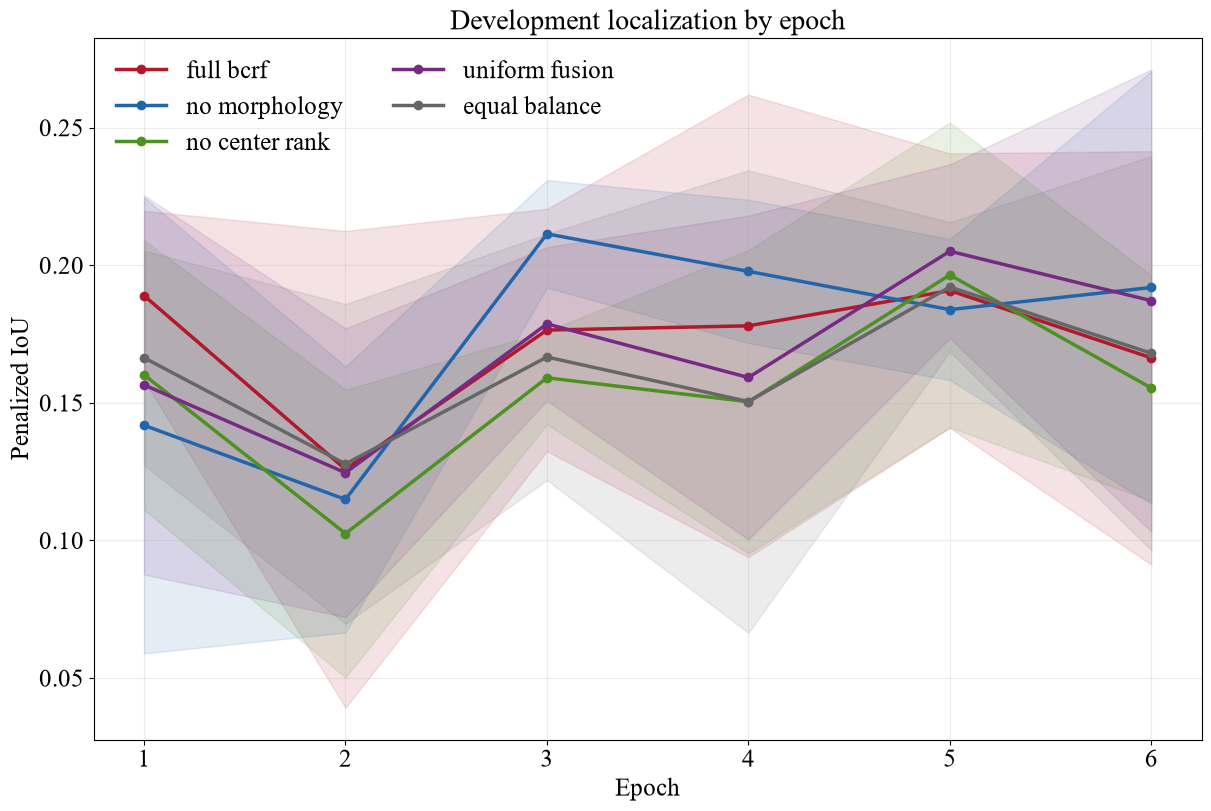

In [18]:
history_plot = pd.read_csv(
    TABLE_DIR / "bcrf_training_history.csv"
)
curve = (
    history_plot.groupby(["variant", "epoch"], as_index=False)
    .agg(
        mean_pIoU=("validation_penalized_iou", "mean"),
        sd_pIoU=("validation_penalized_iou", "std"),
    )
)
colors = {
    "full_bcrf": "#B2182B",
    "no_morphology": "#2166AC",
    "no_center_rank": "#4D9221",
    "uniform_fusion": "#762A83",
    "equal_balance": "#666666",
}
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
for variant in VARIANTS:
    frame = curve[curve["variant"].eq(variant)]
    ax.plot(
        frame["epoch"],
        frame["mean_pIoU"],
        marker="o",
        linewidth=2.5,
        label=variant.replace("_", " "),
        color=colors[variant],
    )
    ax.fill_between(
        frame["epoch"],
        frame["mean_pIoU"] - frame["sd_pIoU"],
        frame["mean_pIoU"] + frame["sd_pIoU"],
        color=colors[variant],
        alpha=0.12,
    )
ax.set(
    title="Development localization by epoch",
    xlabel="Epoch",
    ylabel="Penalized IoU",
)
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
for suffix in ("png", "pdf"):
    fig.savefig(
        DEVELOPMENT_FIGURE_DIR
        / f"bcrf_development_pIoU_by_epoch.{suffix}",
        dpi=350 if suffix == "png" else None,
        bbox_inches="tight",
    )
plt.show()

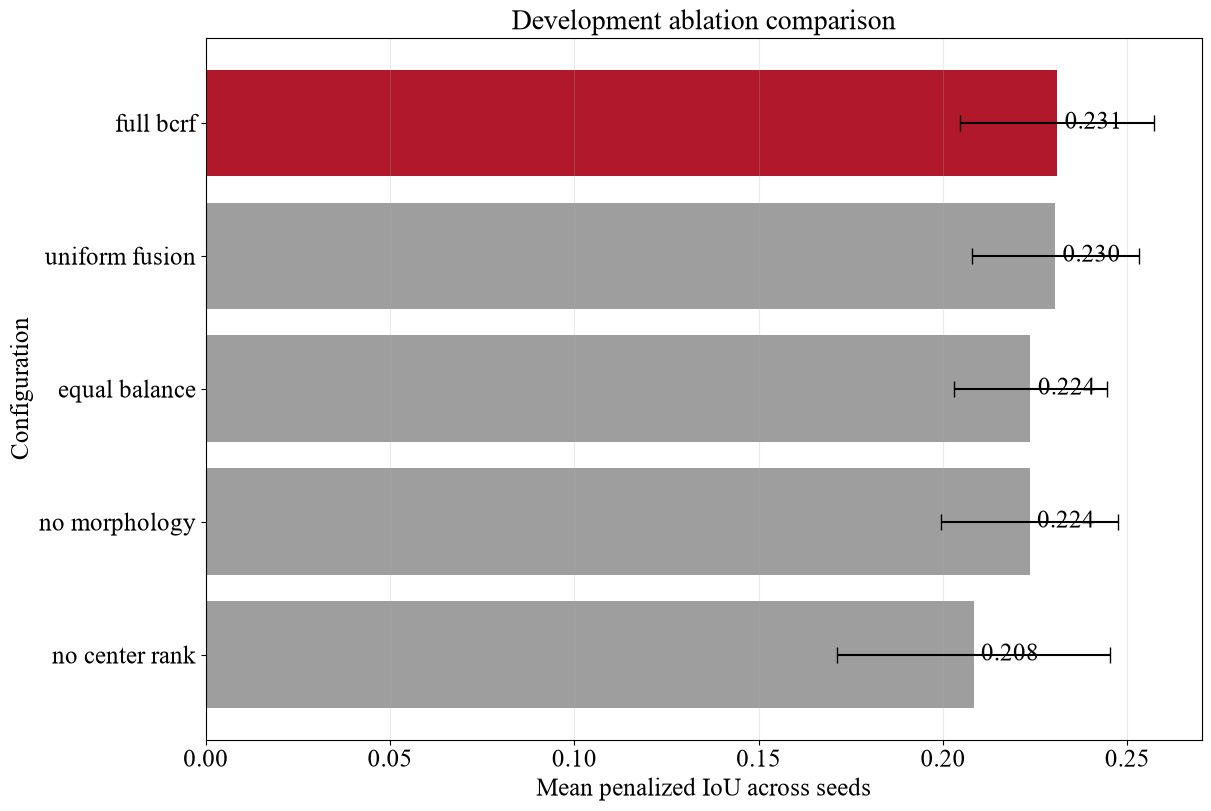

In [19]:
plot_frame = ablation_summary.sort_values(
    "penalized_iou_mean",
    ascending=True,
)
bar_colors = [
    "#B2182B" if value == "full_bcrf" else "#9E9E9E"
    for value in plot_frame["variant"]
]
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
ax.barh(
    plot_frame["variant"].str.replace("_", " "),
    plot_frame["penalized_iou_mean"],
    xerr=plot_frame["penalized_iou_sd"],
    color=bar_colors,
    capsize=6,
)
ax.set(
    title="Development ablation comparison",
    xlabel="Mean penalized IoU across seeds",
    ylabel="Configuration",
)
ax.grid(axis="x", alpha=0.25)
for index, value in enumerate(plot_frame["penalized_iou_mean"]):
    ax.text(
        value + 0.002,
        index,
        f"{value:.3f}",
        va="center",
        fontsize=18,
    )
for suffix in ("png", "pdf"):
    fig.savefig(
        DEVELOPMENT_FIGURE_DIR
        / f"bcrf_development_ablation_pIoU.{suffix}",
        dpi=350 if suffix == "png" else None,
        bbox_inches="tight",
    )
plt.show()

In [ ]:
EVALUATION_SPEC = {
    "role": "development model selection",
    "primary_endpoint": (
        "conditional penalized IoU averaged image-to-study, "
        "then across seeds, positive studies only"
    ),
    "coordinates": "continuous half-open xyxy",
    "max_predicted_boxes": MAX_PREDICTED_BOXES,
    "bootstrap": "10000 paired study-cluster resamples",
    "multiplicity": "Holm within four ablation contrasts",
    "presence": "separate threshold-free AUROC/AUPRC endpoint",
    "forbidden_before_freeze": [
        "secondary_source_test",
        "locked_test",
        "external_test",
    ],
}
EVALUATION_SPEC_SHA256 = canonical_sha256(EVALUATION_SPEC)

lineage_rows = []
for variant, seed in schedule:
    path = checkpoint_path(variant, seed)
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )
    assert checkpoint["variant"] == variant
    assert checkpoint["seed"] == seed
    assert checkpoint["model_spec_sha256"] == MODEL_SPEC_SHA256
    assert checkpoint["training_config_sha256"] == TRAINING_CONFIG_SHA256
    assert "promoted_from_variant" not in checkpoint
    probe = DICOMHUMapBCRF(variant)
    probe.load_state_dict(checkpoint["model_state"], strict=True)
    del probe
    lineage_rows.append(
        {
            "variant": variant,
            "seed": seed,
            "checkpoint": path.name,
            "checkpoint_sha256": sha256_file(path),
            "model_spec_sha256": MODEL_SPEC_SHA256,
            "training_config_sha256": TRAINING_CONFIG_SHA256,
            "evaluation_spec_sha256": EVALUATION_SPEC_SHA256,
            "manifest_sha256": checkpoint["manifest_sha256"],
            "selected_epoch": checkpoint["selected_epoch"],
        }
    )

checkpoint_lineage = pd.DataFrame(lineage_rows)
checkpoint_lineage.to_csv(
    protocol_table("bcrf_checkpoint_lineage.csv"),
    index=False,
)
freeze_manifest = pd.DataFrame(
    [
        {
            "artifact": "immutable_sample_manifest.csv",
            "sha256": sha256_file(
                RAW_DIR / "immutable_sample_manifest.csv"
            ),
        },
        {
            "artifact": "standard_dicom_1024_metadata.csv",
            "sha256": sha256_file(
                PROCESSED_DIR / "standard_dicom_1024_metadata.csv"
            ),
        },
        {
            "artifact": "bcrf_validation_predictions.csv",
            "sha256": sha256_file(
                TABLE_DIR / "bcrf_validation_predictions.csv"
            ),
        },
        {
            "artifact": "model_spec",
            "sha256": MODEL_SPEC_SHA256,
        },
        {
            "artifact": "training_config",
            "sha256": TRAINING_CONFIG_SHA256,
        },
        {
            "artifact": "evaluation_spec",
            "sha256": EVALUATION_SPEC_SHA256,
        },
    ]
)
freeze_manifest.to_csv(
    protocol_table("bcrf_freeze_manifest.csv"),
    index=False,
)
assert len(checkpoint_lineage) == len(VARIANTS) * len(SEEDS)
assert validation_predictions["split"].eq("validation").all()
BCRF_FROZEN = True


In [ ]:
def state_dict_sha256(
    state_dict: dict[str, torch.Tensor],
) -> str:
    digest = hashlib.sha256()
    for name in sorted(state_dict):
        tensor = state_dict[name].detach().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(str(tensor.dtype).encode("utf-8"))
        digest.update(str(tuple(tensor.shape)).encode("utf-8"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def notebook_source_sha256(path: Path) -> str:
    payload = json.loads(path.read_text(encoding="utf-8"))
    digest = hashlib.sha256()
    for cell in payload["cells"]:
        digest.update(cell["cell_type"].encode("utf-8"))
        digest.update("".join(cell["source"]).encode("utf-8"))
    return digest.hexdigest()

notebook_path = (
    PROJECT_ROOT
    / "notebooks"
    / "03_models_and_experiments.ipynb"
)
implementation_source_sha256 = notebook_source_sha256(
    notebook_path
)

deployment_loader = DataLoader(
    MammographyDataset(
        records[records["split"].eq("validation")].head(2),
        training=False,
        seed=SEEDS[0],
    ),
    batch_size=1,
    num_workers=0,
)
deployment_batches = list(deployment_loader)
if len(deployment_batches) != 2:
    raise ValueError("Two validation trace inputs are required")
deployment_inputs = [
    (
        batch["image"].contiguous(
            memory_format=torch.channels_last
        ),
        batch["valid_mask"],
    )
    for batch in deployment_batches
]
example_inputs = deployment_inputs[0]
trace_check_inputs = deployment_inputs[1:]

deployment_rows = []
for seed in SEEDS:
    source_checkpoint = checkpoint_path("full_bcrf", seed)
    checkpoint = torch.load(
        source_checkpoint,
        map_location="cpu",
        weights_only=False,
    )
    source_state_sha256 = state_dict_sha256(
        checkpoint["model_state"]
    )
    model = DICOMHUMapBCRF("full_bcrf").to(
        memory_format=torch.channels_last
    )
    model.load_state_dict(
        checkpoint["model_state"],
        strict=True,
    )
    model.eval()
    traced = torch.jit.trace(
        model,
        example_inputs,
        strict=False,
        check_trace=True,
        check_inputs=trace_check_inputs,
    )
    traced_state_sha256 = state_dict_sha256(
        traced.state_dict()
    )
    if traced_state_sha256 != source_state_sha256:
        raise ValueError("TorchScript state differs from checkpoint")
    path = MODEL_DIR / (
        f"dicom_humap_bcrf_{MODEL_SPEC_SHA256[:10]}_"
        f"full_seed{seed}.torchscript.pt"
    )
    torch.jit.save(traced, path)

    maximum_difference = 0.0
    for inputs in deployment_inputs:
        with torch.no_grad():
            eager_output = model(*inputs)
            traced_output = traced(*inputs)
        maximum_difference = max(
            maximum_difference,
            max(
                float(
                    (
                        eager_output[key]
                        - traced_output[key]
                    )
                    .abs()
                    .max()
                )
                for key in eager_output
            ),
        )
    if maximum_difference >= 1e-5:
        raise ValueError("Trace equivalence check failed")

    deployment_rows.append(
        {
            "seed": seed,
            "artifact": path.name,
            "sha256": sha256_file(path),
            "source_checkpoint": source_checkpoint.name,
            "source_checkpoint_sha256": sha256_file(
                source_checkpoint
            ),
            "source_state_sha256": source_state_sha256,
            "traced_state_sha256": traced_state_sha256,
            "model_spec_sha256": MODEL_SPEC_SHA256,
            "implementation_source_sha256": (
                implementation_source_sha256
            ),
            "trace_check_inputs": len(deployment_inputs),
            "maximum_trace_difference": maximum_difference,
        }
    )
    del model, traced, eager_output, traced_output

deployment_lineage = pd.DataFrame(deployment_rows)
deployment_lineage.to_csv(
    protocol_table("bcrf_deployment_lineage.csv"),
    index=False,
)
